# 규칙 기반 탐지와 업무별 모델·콜드스타트 설계

연구 주제: **대규모 로그 데이터 기반 비지도 학습 이상탐지 AI 모델 개발**

세 기간 전체 Transaction·Process를 분석합니다. ESB.SQL은 **읽기만** 하며 실행하지 않습니다.

## 먼저 읽을 결론

1. **규칙 먼저, 원본은 보존:** 유효하지 않은 값은 격리하고, F/H는 업무 결과 알림으로 보냅니다. 판정 보류·통계 후보를 확정 장애로 합치지 않습니다.
2. **업무 / 범주 조합 / 통합의 세 수준:** 실제 학습·검증 지원량과 시험 콜드스타트 비율로 분할 후보를 비교합니다. 기간 자체는 모델 그룹이 아닙니다.
3. **신규 업무는 공통 모델로 시작:** 지원 가능한 범주 그룹이 있으면 그 모델을 함께 쓰고, 신규 업무 모델은 검증 이후 점진적으로 가중치를 늘립니다.
4. **분위수는 고정 버전:** 학습 구간에서만 p99/p99.9를 계산합니다. 데이터 추가 때마다 재계산하지 않으며 재보정은 별도 버전입니다.

이 노트북은 **규칙 평가와 분할 전략의 데이터 근거**를 실행합니다. 새로운 그룹 AI 모델·앙상블·딥러닝을 학습하거나 성능 우열을 입증하지는 않습니다.

> 공개 저장소용 연구 스냅샷입니다. 원본·평가 데이터셋과 학습/검증 캐시, 행별 예측 배열은 포함하지 않습니다. 개별 원본 로그 미리보기 출력은 제거했습니다. 집계 표와 그림은 저장된 실험 결과이며, 원본 기반 분석을 재실행하려면 별도 데이터가 필요합니다.

## 목차

1. 설정과 SQL 정의
2. 전체 데이터·Status·완료 정보
3. 하드 룰 / 설정 정책 / 조건부 정합성
4. Status별 지연과 업무 안의 비교
5. 학습 구간에서 고정한 p99/p99.9
6. 모델 분할의 지원량·분산·콜드스타트
7. 계층 라우팅·앙상블·검증 계획

각 절은 **계산 코드 → 실제 표·그림 → 의미와 설계 반영** 순서로 읽습니다. 결과 CSV 저장 셀은 없습니다.

In [1]:
from pathlib import Path
import sys, json, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "code" / "log_analysis_common.py").exists() and (p / "data").is_dir())
if str(ROOT / "code") not in sys.path:
    sys.path.insert(0, str(ROOT / "code"))
from log_analysis_common import load_logs, add_time_features, chronological_split, text, setup_plotting
from rule_strategy_common import (STATUS_MEANINGS, resolve_config, schema_audit, rule_book,
    evaluate_rules, rule_counts, hub_aware_summary, add_group_fields, grouping_profile,
    freeze_quantiles, score_frozen_quantiles)

setup_plotting()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 70)
PERIOD_LABELS = {"25년12월24일-26년4월6일": "① 초기", "26년8월15일-26년9월14일": "② 중간", "26년9월30일-26년10월2일": "③ 최근"}
COLORS = ["#3366a8", "#16877a", "#df9639"]

def explain(title, facts, meaning, design):
    display(Markdown(f"**{title}**\n\n{facts}\n\n**의미:** {meaning}\n\n**설계 반영:** {design}"))

def status_profile(frame, kind):
    g = frame.groupby(["source_period", "status"], observed=True, dropna=False)
    out = g.agg(rows=("transactionId", "size"), valid_duration=("duration_ms", "count"),
                p50_ms=("duration_ms", "median"), p95_ms=("duration_ms", lambda x: x.quantile(.95)),
                p99_ms=("duration_ms", lambda x: x.quantile(.99)),
                missing_end=("endTime", lambda x: x.isna().sum()))
    out["missing_end_pct"] = 100 * out.missing_end / out.rows
    out["kind"] = kind
    return out.reset_index()

def rule_plot(audit, rule_names, title):
    subset = audit.loc[audit.rule.isin(rule_names)].copy()
    subset["period"] = subset.period.map(PERIOD_LABELS)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    pivot = subset.pivot(index="rule", columns="period", values="hits").reindex(rule_names)
    pivot.plot.barh(ax=axes[0], color=COLORS, logx=True)
    axes[0].set(xlabel="후보 건수 (로그 눈금; 0은 막대 없음)", ylabel="", title="건수")
    rates = subset.pivot(index="rule", columns="period", values="hit_pct").reindex(rule_names)
    sns.heatmap(rates, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=100, ax=axes[1], cbar=False)
    axes[1].set(xlabel="", ylabel="", title="비교 가능한 행 중 비율 (%)")
    fig.suptitle(title); fig.tight_layout(); plt.show()

## 1. 설정: 입력값이 없으면 default, 의도한 0/False/빈 목록은 유지

다음 셀의 `USER_RULE_OVERRIDES`에 필요한 값만 넣습니다. 생략한 키만 default를 사용합니다.
잘못된 이름/음수 임계값/잘못된 시간대/정규식은 즉시 오류로 알려줍니다.

- `business_alert_statuses`: default F/H. Z는 데이터없음 결과이며 자동 실패로 합치지 않습니다.
- `pending_timeout_ms`: default None. SLA 미제공 시 타임아웃은 비활성입니다.
- 금지 업무·패턴·허용 시간대: default 빈 설정. TEST라는 이름이나 드문 범주를 자동으로 금지하지 않습니다.
- `count_conservation_confirmed`: default False. 계수 정의가 확정되기 전에는 검토로 분류합니다.
- 그룹 최소량 500학습/100검증/3관측일, 분위수 최소량 1,000(p99)/10,000(p99.9)은 **실험 시작값**이지 검증된 최적값이 아닙니다.

In [2]:
USER_RULE_OVERRIDES = {}  # 예: {"business_alert_statuses": ["F"], "time_tolerance_ms": 0}
# USER_RULE_OVERRIDES 예시:
# {"blocked_interfaces": ["운영자가 지정한 업무"],
#  "allowed_hours_by_interface": {"운영자가 지정한 배치": [0, 1, 2, 3]},
#  "pattern_rules": [{"name": "지정 조합", "conditions": {"interfaceId": "업무A", "status": "F"}}]}
CONFIG = resolve_config(USER_RULE_OVERRIDES)
OBSERVED_AS_OF = None  # 실제 수집 cutoff를 확인한 경우만 기간별 Timestamp 사전 입력
display(pd.DataFrame([(k, json.dumps(v, ensure_ascii=False)) for k, v in CONFIG.items()], columns=["설정", "적용 값"]))
display(pd.DataFrame(STATUS_MEANINGS.items(), columns=["STATUS", "사용자 제공 의미"]))

,설정,적용 값
0,version,"""rules-v1-20261006"""
1,allowed_statuses,"[""S"", ""F"", ""P"", ""N"", ""H"", ""Z""]"
2,final_statuses,"[""S"", ""F"", ""H"", ""Z""]"
3,business_alert_statuses,"[""F"", ""H""]"
4,time_tolerance_ms,1.0
5,pending_timeout_ms,null
6,blocked_interfaces,[]
7,pattern_rules,[]
8,allowed_hours_by_interface,{}
9,success_response_codes,"[""0000""]"


,STATUS,사용자 제공 의미
0,S,성공
1,F,실패
2,P,처리중
3,N,미처리
4,H,부분성공
5,Z,데이터없음


### 1.1 SQL에서 확정되는 것과 확정되지 않는 것

Transaction PK: **TRANSACTION_ID + PROCESS_HUB_ID + RETRY_COUNT**.
Process PK: **TRANSACTION_ID + PROCESS_ID + RETRY_COUNT**. PROCESS_HUB_ID도 NOT NULL입니다.

STATUS·시작/종료시각·카운트는 SQL상 nullable입니다. SQL은 상태별 종료 의무, 성공 응답코드,
total=success+error, 거래/단계 상태 전파를 CHECK/FK로 강제하지 않습니다.
따라서 이들을 모두 ‘SQL상 불가능한 오류’라고 부르면 안 됩니다.

데이터 연결은 기간 + 거래 ID + 허브 + 재시도를 사용하고, 매칭하지 못한 행은 검토로 남깁니다.
향후 재시도 단계 번호와 거래 재시도 번호가 다른 시스템이면 연결 계약을 별도로 정해야 합니다.

In [3]:
sql_text = (ROOT / "data" / "ESB.SQL").read_text(encoding="utf-8-sig")
schema = schema_audit(sql_text)
display(schema.loc[schema.table.isin(["EC_TRANSACTION_MONITORING", "EC_PROCESS_MONITORING"])])
display(rule_book(CONFIG))
explain("DDL 확인", f"전체 {schema.table.nunique()}개 테이블, {len(schema)}개 컬럼 정의를 읽었습니다.",
        "메시지 테이블 정의도 확인하지만 이번 수치 분석은 Transaction/Process 범위입니다. DDL은 실행하지 않습니다.",
        "SQL 불변 제약과 운영 계약·통계 기준을 서로 다른 종류로 관리합니다.")

,table,column,type,sql_not_null,primary_key,meaning
0,EC_TRANSACTION_MONITORING,TRANSACTION_ID,VARCHAR2(80),True,True,트랜잭션 아이디
1,EC_TRANSACTION_MONITORING,INTERFACE_ID,VARCHAR2(30),False,False,인터페이스 아이디
2,EC_TRANSACTION_MONITORING,PROCESS_HUB_ID,VARCHAR2(20),True,True,처리 허브 아이디
3,EC_TRANSACTION_MONITORING,START_CHANNEL_ID,VARCHAR2(20),False,False,시작 채널 아이디
4,EC_TRANSACTION_MONITORING,END_CHANNEL_ID,VARCHAR2(20),False,False,종료 채널 아이디
5,EC_TRANSACTION_MONITORING,PROCESS_COUNT,NUMBER,False,False,프로세스 수
6,EC_TRANSACTION_MONITORING,STATUS,VARCHAR2(10),False,False,처리 상태 코드
7,EC_TRANSACTION_MONITORING,RESPONSE_CODE,VARCHAR2(10),False,False,응답 코드
8,EC_TRANSACTION_MONITORING,RESPONSE_MESSAGE,VARCHAR2(500),False,False,응답 메시지
9,EC_TRANSACTION_MONITORING,INTERFACE_TYPE,VARCHAR2(10),False,False,인터페이스 타입


,rule,type,condition,action,precondition
0,missing_sql_key,SQL 불변,PK/NOT NULL 필드 결측,quarantine,SQL 정의
1,duplicate_sql_key,SQL 불변,동일 기간 내 복합 PK 충돌,quarantine,원본 exact duplicate 제거 후 충돌
2,invalid_status,상태 사전,결측이 아닌 상태가 S/F/P/N/H/Z 밖,quarantine,사용자 제공 상태 사전
3,negative_duration,시각 정합성,종료가 시작보다 tolerance 이상 앞섬,quarantine,서로 동일 실행·동일 시계라는 전제
4,invalid_count_domain,도메인 규칙,건수/재시도 값이 음수 또는 비정수,quarantine,SQL NUMBER 자체는 CHECK를 선언하지 않음
5,missing_status,품질 검토,상태가 비어 있음,review,SQL STATUS는 nullable
6,missing_start,품질 검토,시작시각 없음,review,SQL START_TIME은 nullable
7,final_missing_end,완료/수집 검토,S/F/H/Z인데 종료시각 없음,review,N/P의 종료 결측과 구분
8,business_status,설정형 정책,설정한 F/H 상태,business_alert,실행 결과 알림; 확정 AI 이상 정답 아님
9,pending_timeout,설정형 정책,N/P 경과시간이 설정 SLA 초과,business_alert,default=None: 비활성; 실제 관측 cutoff 필수


**DDL 확인**

전체 4개 테이블, 51개 컬럼 정의를 읽었습니다.

**의미:** 메시지 테이블 정의도 확인하지만 이번 수치 분석은 Transaction/Process 범위입니다. DDL은 실행하지 않습니다.

**설계 반영:** SQL 불변 제약과 운영 계약·통계 기준을 서로 다른 종류로 관리합니다.

## 2. 세 기간 전체 로드와 관측 품질

파일명이 뒤바뀐 최근 자료도 내용의 스키마로 찾습니다. 기존 공통 로더를 재사용하며 exact duplicate 제거 수,
시각/수치 파싱 실패, 출처, 관측 범위를 함께 표시합니다. 기존 노트북은 수정하지 않습니다.

In [4]:
transactions, transaction_audit = load_logs("transaction", ROOT / "data")
processes, process_audit = load_logs("process", ROOT / "data")
transactions = add_group_fields(add_time_features(transactions))
processes = add_group_fields(add_time_features(processes))
display(transaction_audit); display(process_audit)
print(f"전체 Transaction={len(transactions):,}, Process={len(processes):,}, 입력 합={len(transactions)+len(processes):,}")

,source_period,source_file,format,raw_rows,rows,exact_duplicates_removed,...,invalid_numeric_values,first_start,last_start,last_end,observed_days,file_MB
0,25년12월24일-26년4월6일,25년12월24일-26년4월6일\EC_TRANSACTION_MONITORING.csv,csv,1768054,1768054,0,...,0,2025-12-24 10:25:31.632,2026-04-06 08:51:33.002,2026-04-06 08:52:21.416,59,317.01
1,26년8월15일-26년9월14일,26년8월15일-26년9월14일\transactions.csv,csv,213381,213381,0,...,0,2026-08-15 00:00:00.257,2026-09-14 14:19:58.603,2026-09-14 14:20:09.431,19,36.65
2,26년9월30일-26년10월2일,26년9월30일-26년10월2일\EC_MESSAGE_BODY.csv,sql,27268,27268,0,...,0,2026-09-30 09:49:26.483,2026-10-02 15:36:59.444,2026-10-02 15:36:59.698,3,13.03


,source_period,source_file,format,raw_rows,rows,exact_duplicates_removed,...,invalid_numeric_values,first_start,last_start,last_end,observed_days,file_MB
0,25년12월24일-26년4월6일,25년12월24일-26년4월6일\EC_PROCESS_MONITORING.csv,csv,3473285,3473285,0,...,0,2025-12-24 10:25:31.689,2026-04-06 08:51:33.531,2026-04-06 08:52:21.391,60,557.08
1,26년8월15일-26년9월14일,26년8월15일-26년9월14일\processes.csv,csv,213509,213509,0,...,0,2026-08-15 00:00:00.284,2026-09-14 14:19:59.710,2026-09-14 14:20:09.407,19,37.05
2,26년9월30일-26년10월2일,26년9월30일-26년10월2일\EC_TRANSACTION_MONITORING.csv,csv,27405,27405,0,...,0,2026-09-30 09:49:26.494,2026-10-02 15:36:59.559,2026-10-02 15:36:59.685,3,4.90


전체 Transaction=2,008,703, Process=3,714,199, 입력 합=5,722,902


### 2.1 Status 구성과 종료시각 결측: P/N을 실패로 합치지 않기

S=성공, F=실패, P=처리중, N=미처리, H=부분성공, Z=데이터없음입니다.
P/N의 endTime 결측은 완료 로그 누락과 다르게 해석해야 합니다. 스냅샷 시각·SLA 없이 오래 대기했다고 확정하지 않습니다.

,kind,source_period,status,rows,valid_duration,missing_end,missing_end_pct
0,Transaction,25년12월24일-26년4월6일,F,306172,306172,0,0.000
1,Transaction,25년12월24일-26년4월6일,H,58,58,0,0.000
2,Transaction,25년12월24일-26년4월6일,P,7061,1,7060,99.986
3,Transaction,25년12월24일-26년4월6일,S,1454528,1454528,0,0.000
4,Transaction,25년12월24일-26년4월6일,Z,235,235,0,0.000
5,Transaction,26년8월15일-26년9월14일,F,132036,132036,0,0.000
6,Transaction,26년8월15일-26년9월14일,H,1,1,0,0.000
7,Transaction,26년8월15일-26년9월14일,S,81344,81344,0,0.000
8,Transaction,26년9월30일-26년10월2일,F,43,43,0,0.000
9,Transaction,26년9월30일-26년10월2일,H,2,2,0,0.000


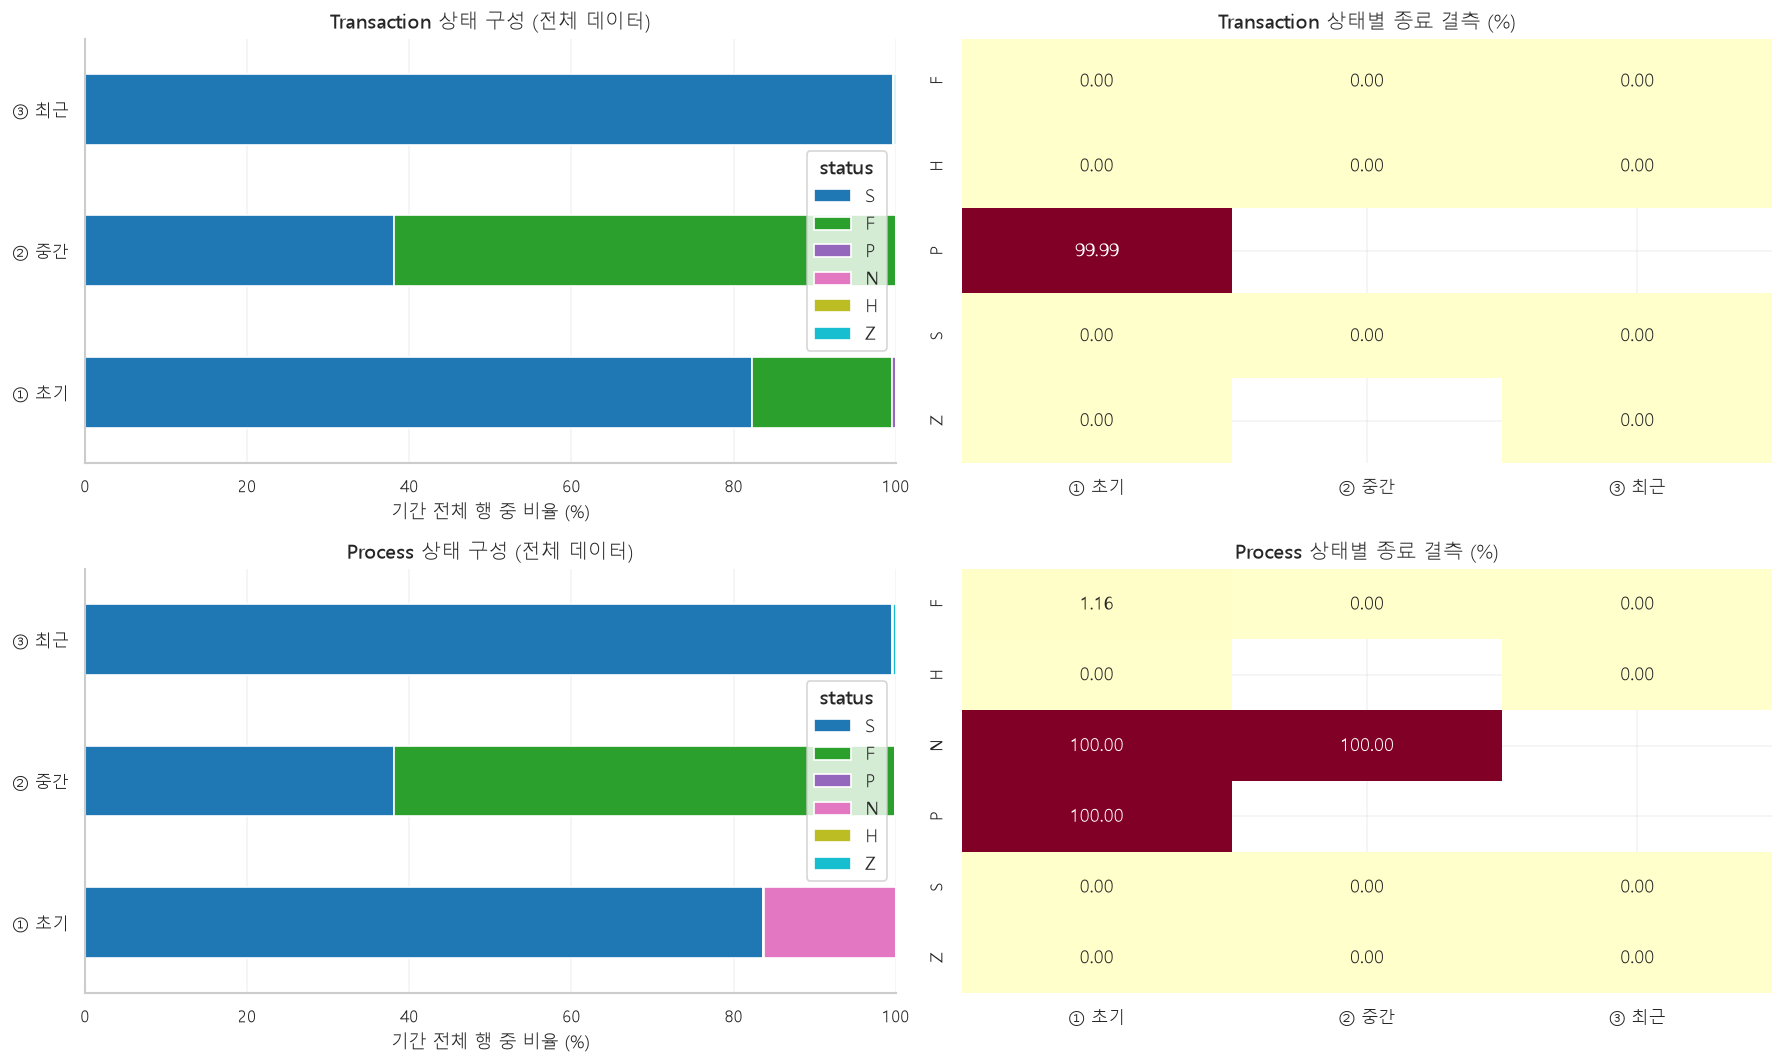

**Status/결측 교차 분석**

표의 분모는 각 기간·Status의 전체 행입니다. 빈 칸은 해당 집단이 없어 계산할 수 없다는 뜻입니다.

**의미:** 실패 비율과 미처리/처리중 비율은 별개입니다. 성공도 운영상 이상을 포함할 수 있어 정상 정답으로 확정하지 않습니다.

**설계 반영:** F/H는 결과 알림, P/N은 진행 상태 감시, Z는 데이터 없음 결과로 각각 처리합니다.

In [5]:
status_stats = pd.concat([status_profile(transactions, "Transaction"), status_profile(processes, "Process")], ignore_index=True)
display(status_stats[["kind", "source_period", "status", "rows", "valid_duration", "missing_end", "missing_end_pct"]].round(3))
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for row, (kind, frame) in enumerate([("Transaction", transactions), ("Process", processes)]):
    rates = pd.crosstab(frame.source_period, text(frame.status), normalize="index").mul(100).rename(index=PERIOD_LABELS)
    rates.reindex(columns=list(STATUS_MEANINGS), fill_value=0).plot.barh(stacked=True, ax=axes[row, 0], colormap="tab10")
    axes[row, 0].set(title=kind + " 상태 구성 (전체 데이터)", xlabel="기간 전체 행 중 비율 (%)", ylabel="", xlim=(0, 100))
    missing = status_stats.loc[status_stats.kind.eq(kind)].pivot(index="status", columns="source_period", values="missing_end_pct").rename(columns=PERIOD_LABELS)
    sns.heatmap(missing, annot=True, fmt=".2f", vmin=0, vmax=100, ax=axes[row, 1], cmap="YlOrRd", cbar=False)
    axes[row, 1].set(title=kind + " 상태별 종료 결측 (%)", xlabel="", ylabel="")
fig.tight_layout(); plt.show()
explain("Status/결측 교차 분석", "표의 분모는 각 기간·Status의 전체 행입니다. 빈 칸은 해당 집단이 없어 계산할 수 없다는 뜻입니다.",
        "실패 비율과 미처리/처리중 비율은 별개입니다. 성공도 운영상 이상을 포함할 수 있어 정상 정답으로 확정하지 않습니다.",
        "F/H는 결과 알림, P/N은 진행 상태 감시, Z는 데이터 없음 결과로 각각 처리합니다.")

## 3. 규칙 평가: 격리 / 업무 알림 / 품질 검토를 분리

고정 규칙은 데이터가 추가돼도 식이 바뀌지 않습니다. 입력 설정은 버전으로 관리합니다.
조건을 계산할 수 없는 행은 false 정상 대신 **비교 불가 분모**에 남깁니다.

In [6]:
tx_rules, tx_rule_eligible = evaluate_rules(transactions, "transaction", CONFIG, observed_as_of=OBSERVED_AS_OF)
pr_rules, pr_rule_eligible = evaluate_rules(processes, "process", CONFIG, observed_as_of=OBSERVED_AS_OF)
rule_audit = pd.concat([rule_counts(transactions, tx_rules, tx_rule_eligible, "Transaction"),
                        rule_counts(processes, pr_rules, pr_rule_eligible, "Process")], ignore_index=True)
display(rule_audit.round(4))

,kind,period,rule,rows,eligible,hits,hit_pct,not_evaluable
0,Transaction,25년12월24일-26년4월6일,missing_sql_key,1768054,1768054,0,0.0,0
1,Transaction,25년12월24일-26년4월6일,duplicate_sql_key,1768054,1768054,0,0.0,0
2,Transaction,25년12월24일-26년4월6일,invalid_status,1768054,1768054,0,0.0,0
3,Transaction,25년12월24일-26년4월6일,missing_status,1768054,1768054,0,0.0,0
4,Transaction,25년12월24일-26년4월6일,missing_start,1768054,1768054,0,0.0,0
...,...,...,...,...,...,...,...,...
79,Process,26년9월30일-26년10월2일,pending_timeout,27405,0,0,NaN,27405
80,Process,26년9월30일-26년10월2일,configured_pattern,27405,0,0,NaN,27405
81,Process,26년9월30일-26년10월2일,response_convention,27405,27317,0,0.0,88
82,Process,26년9월30일-26년10월2일,count_conservation,27405,27405,0,0.0,0


### 3.1 관계 규칙: 거래 성공인데 기대 단계가 모두 실패 / 단계 수 불일치

‘모두 F’는 기대 단계 전체를 실제로 관측한 경우에만 계산합니다. 한 단계만 F이고 나머지 로그가 없으면
모두 실패라고 단정하지 않습니다. Process가 여러 재시도에 걸친 경우도 동일 시도만 비교합니다.

선행 종료 전 시작이나 거래 경계 이탈은 비동기/시계 오차일 수 있으므로 hard quarantine에 포함하지 않습니다.

In [ ]:
transaction_summary, hub_join_audit = hub_aware_summary(transactions, processes)
assert transaction_summary.transactionId.astype("string").equals(transactions.transactionId.astype("string"))
relation_audit = transaction_summary.groupby("source_period", observed=True).agg(
    transactions=("transactionId", "size"), relation_comparable=("relation_comparable", "sum"),
    count_mismatch=("process_count_mismatch", "sum"), no_process=("no_process", "sum"),
    success_all_F=("tx_success_all_process_failed", "sum"), success_any_F=("tx_success_any_process_failed", "sum"))
display(hub_join_audit); display(relation_audit)
display(transaction_summary.loc[transaction_summary.tx_success_all_process_failed,
    ["source_period", "transactionId", "processHubId", "retryCount", "status", "processCount", "observed_processes", "process_failed"]].head(15))
relation_review = transaction_summary.process_count_mismatch | transaction_summary.no_process | transaction_summary.tx_success_any_process_failed
tx_rules["quality_review"] |= relation_review
tx_rules["reference_eligible"] &= ~relation_review
explain("안전한 관계 검토", f"전체 기대 단계가 관측됐는데 Tx S/모든 Process F인 후보: {transaction_summary.tx_success_all_process_failed.sum():,}건.",
        "이전 many-to-one 분석과 달리 허브·재시도까지 맞춘 연결입니다. 결과가 다르면 키 정의 차이부터 확인합니다.",
        "관계 불일치는 검토/학습 제외로 유지합니다. 운영 전파 계약과 수집 완전성이 확인된 뒤 차단 수준을 승인합니다.")

### 3.2 설정 없는 정책은 비활성, 원본은 삭제하지 않음

공통 default 정책: F/H 알림만 활성. 금지 업무·패턴·허용 시간대·P/N 타임아웃은 사용자 설정 전에는 비활성입니다.
`reference_eligible`은 성공·완료·규칙 비위반의 보수적인 학습 후보입니다. 확정 정상 라벨은 아니며 다른 학습 정책과 비교해야 합니다.

,kind,period,rows,quarantine,business_alert,quality_review,reference_eligible
0,Transaction,① 초기,1768054,0,306230,12892,1454517
1,Transaction,② 중간,213381,0,132037,30,81342
2,Transaction,③ 최근,27268,0,45,14,27180
3,Process,① 초기,3473285,0,896,370,2904425
4,Process,② 중간,213509,0,131894,16,81461
5,Process,③ 최근,27405,0,32,0,27287


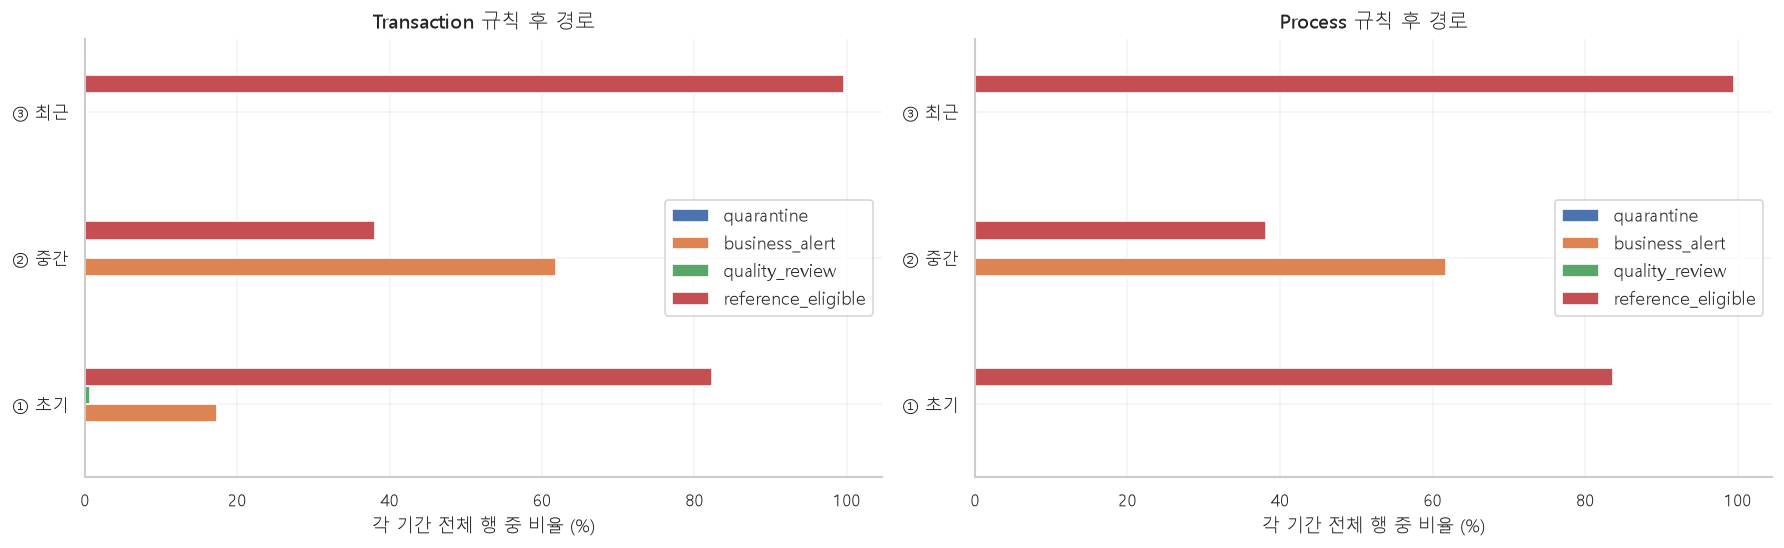

**규칙 이후 경로**

격리·알림·검토는 서로 겹칠 수 있으므로 위 합계를 전체 이상 수로 더하지 않습니다.

**의미:** F/H 필터링은 정상 기준 학습의 정책이며 실패 데이터를 원본에서 삭제하는 과정이 아닙니다.

**설계 반영:** 학습 후보에서 제외된 로그도 별도 경보와 사후 평가용으로 보존합니다. S에서 발생하는 행동 이상도 모델이 검토합니다.

In [8]:
triage_rows = []
for kind, frame, flags in [("Transaction", transactions, tx_rules), ("Process", processes, pr_rules)]:
    for period, idx in frame.groupby("source_period", observed=True).groups.items():
        triage_rows.append({"kind": kind, "period": PERIOD_LABELS[str(period)], "rows": len(idx),
            **{name: int(flags.loc[idx, name].sum()) for name in ["quarantine", "business_alert", "quality_review", "reference_eligible"]}})
triage = pd.DataFrame(triage_rows)
display(triage)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.7))
for ax, kind in zip(axes, ["Transaction", "Process"]):
    t = triage.loc[triage.kind.eq(kind)].set_index("period")
    t[["quarantine", "business_alert", "quality_review", "reference_eligible"]].div(t.rows, axis=0).mul(100).plot.barh(ax=ax)
    ax.set(title=kind + " 규칙 후 경로", xlabel="각 기간 전체 행 중 비율 (%)", ylabel="")
fig.tight_layout(); plt.show()
explain("규칙 이후 경로", "격리·알림·검토는 서로 겹칠 수 있으므로 위 합계를 전체 이상 수로 더하지 않습니다.",
        "F/H 필터링은 정상 기준 학습의 정책이며 실패 데이터를 원본에서 삭제하는 과정이 아닙니다.",
        "학습 후보에서 제외된 로그도 별도 경보와 사후 평가용으로 보존합니다. S에서 발생하는 행동 이상도 모델이 검토합니다.")

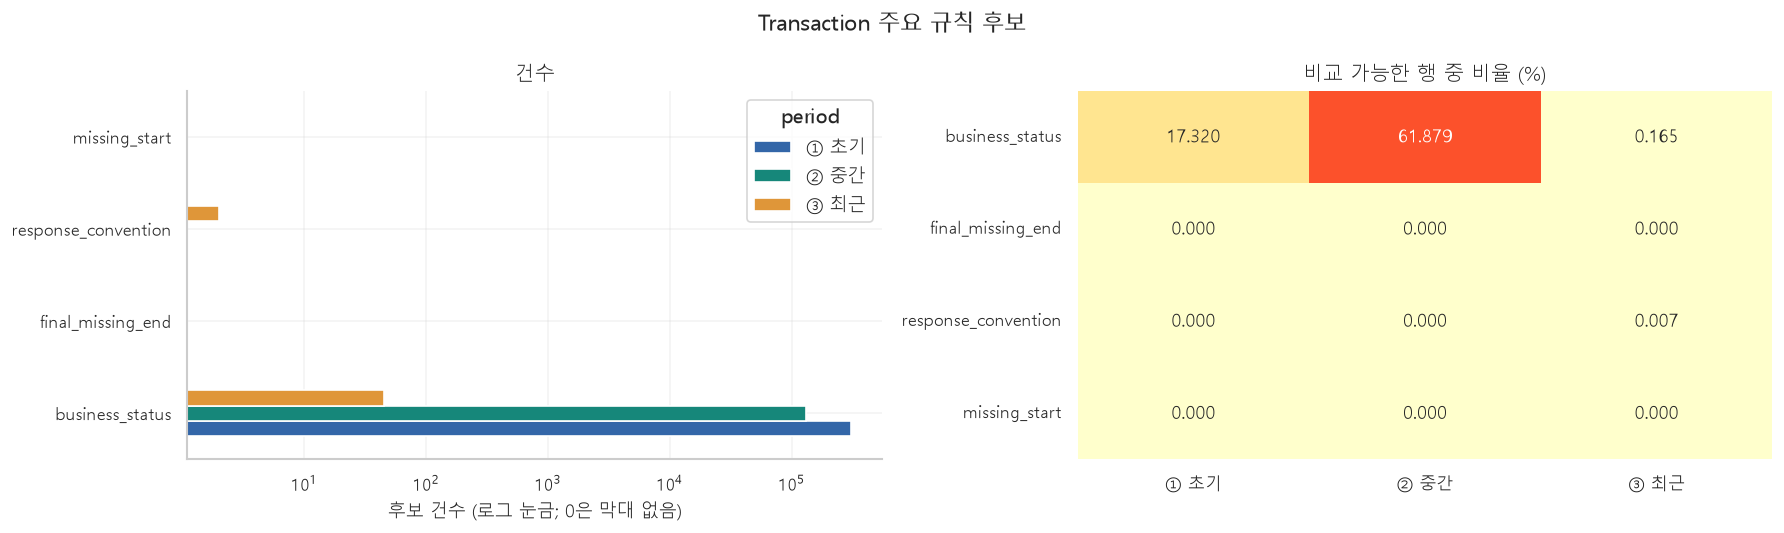

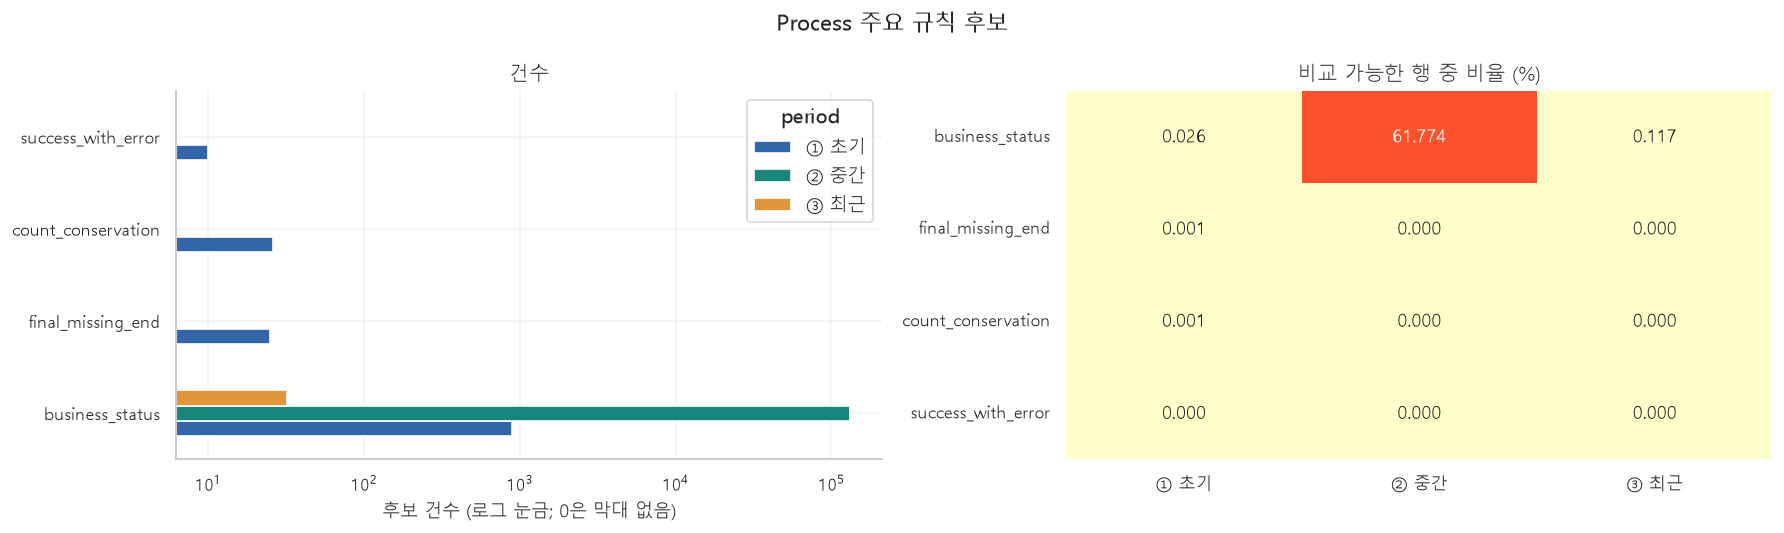

,kind,period,rule,eligible,hits,hit_pct
9,Transaction,25년12월24일-26년4월6일,pending_timeout,0,0,NaN
10,Transaction,25년12월24일-26년4월6일,blocked_interface,0,0,NaN
11,Transaction,25년12월24일-26년4월6일,outside_allowed_hours,0,0,NaN
12,Transaction,25년12월24일-26년4월6일,configured_pattern,0,0,NaN
23,Transaction,26년8월15일-26년9월14일,pending_timeout,0,0,NaN
24,Transaction,26년8월15일-26년9월14일,blocked_interface,0,0,NaN
25,Transaction,26년8월15일-26년9월14일,outside_allowed_hours,0,0,NaN
26,Transaction,26년8월15일-26년9월14일,configured_pattern,0,0,NaN
37,Transaction,26년9월30일-26년10월2일,pending_timeout,0,0,NaN
38,Transaction,26년9월30일-26년10월2일,blocked_interface,0,0,NaN


**비활성 정책**

분모 eligible=0이면 비율은 NaN입니다. 후보 0/비교 가능 0은 정상 확인이 아닙니다.

**의미:** 운영자가 금지 조건/SLA를 제공하지 않은 상태에서 임의로 장애를 만들지 않습니다.

**설계 반영:** 활성 정책과 설정 버전, 평가 시각을 함께 기록합니다.

In [9]:
rule_plot(rule_audit.loc[rule_audit.kind.eq("Transaction")],
          ["business_status", "final_missing_end", "response_convention", "missing_start"], "Transaction 주요 규칙 후보")
rule_plot(rule_audit.loc[rule_audit.kind.eq("Process")],
          ["business_status", "final_missing_end", "count_conservation", "success_with_error"], "Process 주요 규칙 후보")
display(rule_audit.loc[rule_audit.rule.isin(["pending_timeout", "blocked_interface", "configured_pattern", "outside_allowed_hours"]),
    ["kind", "period", "rule", "eligible", "hits", "hit_pct"]])
explain("비활성 정책", "분모 eligible=0이면 비율은 NaN입니다. 후보 0/비교 가능 0은 정상 확인이 아닙니다.",
        "운영자가 금지 조건/SLA를 제공하지 않은 상태에서 임의로 장애를 만들지 않습니다.",
        "활성 정책과 설정 버전, 평가 시각을 함께 기록합니다.")

### 3.3 특정 업무·패턴·시간대 정책을 정하기 위한 후보 분석

Transaction은 업무+Status+응답코드, Process는 어댑터+채널+Status+응답코드 조합의 실제 지원량을 봅니다.
상위 조합이라는 이유로 금지하지는 않습니다. ‘어떤 조건을 운영 정책으로 입력할지’ 결정할 근거입니다.
시간대별 F 비율은 30행 이상일 때만 그리며 관측된 시작 로그 안의 비율입니다.

,source_period,interfaceId,status,responseCode,rows
1307,26년8월15일-26년9월14일,IF_REST_ERROR_RESPONSE,F,4311,78950
1272,26년8월15일-26년9월14일,IF_CLAUDE_CREATE_001,F,4311,37864
93,25년12월24일-26년4월6일,IF_AP2TCP_000,F,4801,26057
14,25년12월24일-26년4월6일,HUB_DB2API_001,F,4801,21660
103,25년12월24일-26년4월6일,IF_AP2TCP_002,F,4801,14466
100,25년12월24일-26년4월6일,IF_AP2TCP_001,F,4801,13631
1232,25년12월24일-26년4월6일,SVC_EXEC_TEST1,F,4801,8536
1278,26년8월15일-26년9월14일,IF_CLAUDE_DELETE_001,F,4311,7737
1275,26년8월15일-26년9월14일,IF_CLAUDE_CREATE_001,F,4999,3692
1309,26년8월15일-26년9월14일,IF_REST_ERROR_RESPONSE,F,4999,3577


,source_period,adapterType,channelId,status,responseCode,rows
232,26년8월15일-26년9월14일,SERVICE.EXECUTOR,HUB,F,4311,124553
233,26년8월15일-26년9월14일,SERVICE.EXECUTOR,HUB,F,4999,7270
55,25년12월24일-26년4월6일,DB.READER,TSC,F,4999,235
76,25년12월24일-26년4월6일,DB.WRITER,SOL,F,4999,108
74,25년12월24일-26년4월6일,DB.WRITER,SOL,F,4102,83
112,25년12월24일-26년4월6일,FILE.READER,TSC,F,4201,50
89,25년12월24일-26년4월6일,DB.WRITER,TSC,F,9999,41
251,26년9월30일-26년10월2일,DB.WRITER,SOL,F,4121,27
77,25년12월24일-26년4월6일,DB.WRITER,SOL,F,9999,22
114,25년12월24일-26년4월6일,FILE.READER,TSC,F,4999,20


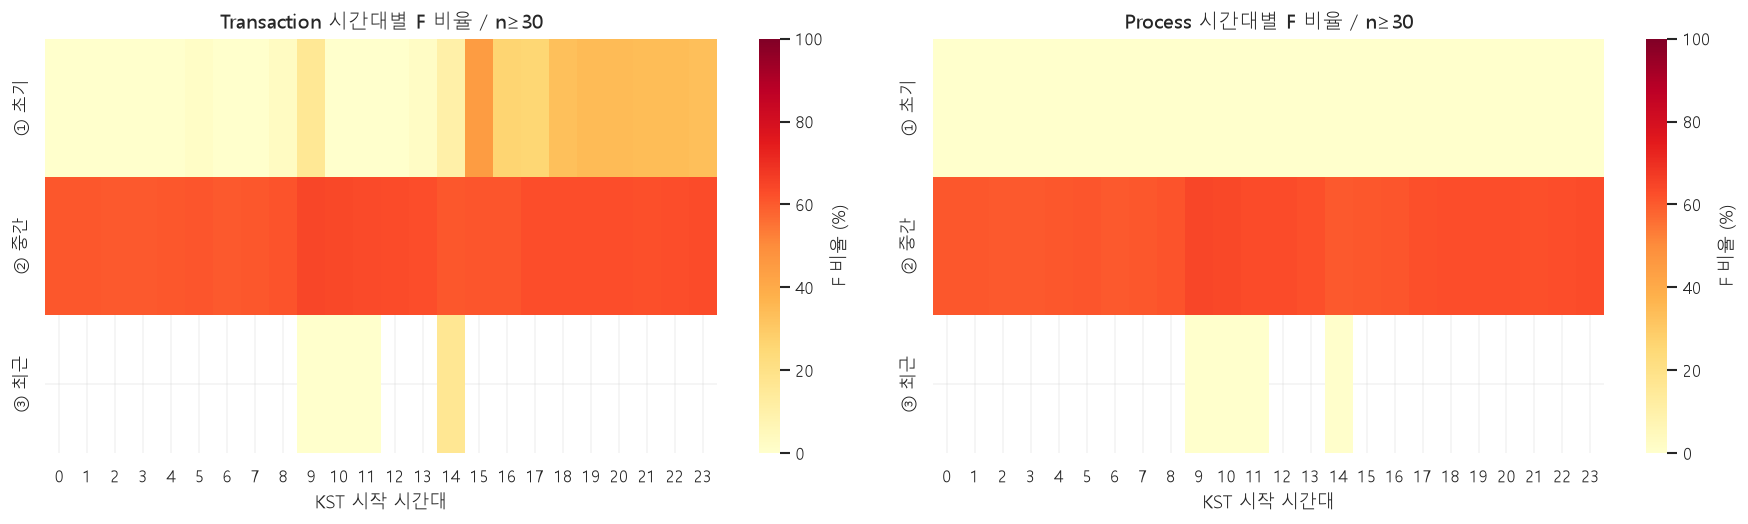

,source_period,hour,rows,failures,failure_pct,kind
33,26년8월15일-26년9월14일,9,8676,5578,64.292,Transaction
87,26년8월15일-26년9월14일,9,8673,5564,64.153,Process
34,26년8월15일-26년9월14일,10,9143,5844,63.918,Transaction
88,26년8월15일-26년9월14일,10,9160,5845,63.810,Process
35,26년8월15일-26년9월14일,11,9300,5899,63.430,Transaction
89,26년8월15일-26년9월14일,11,9317,5881,63.121,Process
36,26년8월15일-26년9월14일,12,9358,5902,63.069,Transaction
90,26년8월15일-26년9월14일,12,9357,5901,63.065,Process
101,26년8월15일-26년9월14일,23,8280,5208,62.899,Process
47,26년8월15일-26년9월14일,23,8280,5208,62.899,Transaction


**정책 도출의 근거**

상위 실패/부분성공 조합과 관측 시간대별 F 비율을 비교했습니다. 회색 칸은 로그 없음/지원 부족입니다.

**의미:** 실패가 반복되는 조합은 결과 알림을 좁히는 후보입니다. 야간·특정 업무·높은 실패율을 자동 금지하거나 전체 시간대의 장애 확률로 해석하지 않습니다.

**설계 반영:** 패턴·업무·허용 시간대 하드 정책은 실제 운영 계약을 입력해야 활성화됩니다. default는 비활성입니다.

In [10]:
tx_patterns = transactions.groupby(["source_period", "interfaceId", "status", "responseCode"], observed=True, dropna=False).size().rename("rows").reset_index()
pr_patterns = processes.groupby(["source_period", "adapterType", "channelId", "status", "responseCode"], observed=True, dropna=False).size().rename("rows").reset_index()
display(tx_patterns.loc[tx_patterns.status.isin(["F", "H"])].sort_values("rows", ascending=False).head(20))
display(pr_patterns.loc[pr_patterns.status.isin(["F", "H"])].sort_values("rows", ascending=False).head(20))
hour_policy_rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (kind, frame) in zip(axes, [("Transaction", transactions), ("Process", processes)]):
    h = frame.loc[frame.startTime.notna() & frame.status.notna(), ["source_period", "startTime", "status"]].copy()
    h["hour"] = h.startTime.dt.hour; h["failure"] = h.status.eq("F")
    hourly_policy = h.groupby(["source_period", "hour"], observed=True).agg(rows=("status", "size"), failures=("failure", "sum"))
    hourly_policy["failure_pct"] = (100 * hourly_policy.failures / hourly_policy.rows).where(hourly_policy.rows.ge(30))
    hourly_policy["kind"] = kind; hour_policy_rows.append(hourly_policy.reset_index())
    matrix = hourly_policy.failure_pct.unstack("hour").reindex(columns=range(24)).rename(index=PERIOD_LABELS)
    sns.heatmap(matrix, annot=False, vmin=0, vmax=100, cmap="YlOrRd", ax=ax, cbar_kws={"label": "F 비율 (%)"})
    ax.set(title=kind + " 시간대별 F 비율 / n≥30", xlabel="KST 시작 시간대", ylabel="")
fig.tight_layout(); plt.show()
hour_policy_stats = pd.concat(hour_policy_rows, ignore_index=True)
display(hour_policy_stats.sort_values("failure_pct", ascending=False).head(15).round(3))
explain("정책 도출의 근거", "상위 실패/부분성공 조합과 관측 시간대별 F 비율을 비교했습니다. 회색 칸은 로그 없음/지원 부족입니다.",
        "실패가 반복되는 조합은 결과 알림을 좁히는 후보입니다. 야간·특정 업무·높은 실패율을 자동 금지하거나 전체 시간대의 장애 확률로 해석하지 않습니다.",
        "패턴·업무·허용 시간대 하드 정책은 실제 운영 계약을 입력해야 활성화됩니다. default는 비활성입니다.")

## 4. Status에 따른 처리시간 차이

완료 지연을 계산할 수 있는 행만 비교합니다. S/F 이외 상태도 표에는 보존하며,
소수 집단의 p99와 단일 극단값은 충분한 데이터 없이 안정적인 정상 범위가 아닙니다.

,kind,source_period,status,rows,valid_duration,p50_ms,p95_ms,p99_ms
0,Transaction,25년12월24일-26년4월6일,F,306172,306172,4.0,29.00,1421.00
1,Transaction,25년12월24일-26년4월6일,H,58,58,426.0,18890.75,49851.01
2,Transaction,25년12월24일-26년4월6일,P,7061,1,11.0,11.00,11.00
3,Transaction,25년12월24일-26년4월6일,S,1454528,1454528,6329.0,9777.00,11129.00
4,Transaction,25년12월24일-26년4월6일,Z,235,235,89.0,245.00,527.48
5,Transaction,26년8월15일-26년9월14일,F,132036,132036,51.0,77.00,133.00
6,Transaction,26년8월15일-26년9월14일,H,1,1,9721.0,9721.00,9721.00
7,Transaction,26년8월15일-26년9월14일,S,81344,81344,77.0,175.00,1057.57
8,Transaction,26년9월30일-26년10월2일,F,43,43,7426.0,15145.60,28196.34
9,Transaction,26년9월30일-26년10월2일,H,2,2,3142.0,3314.80,3330.16


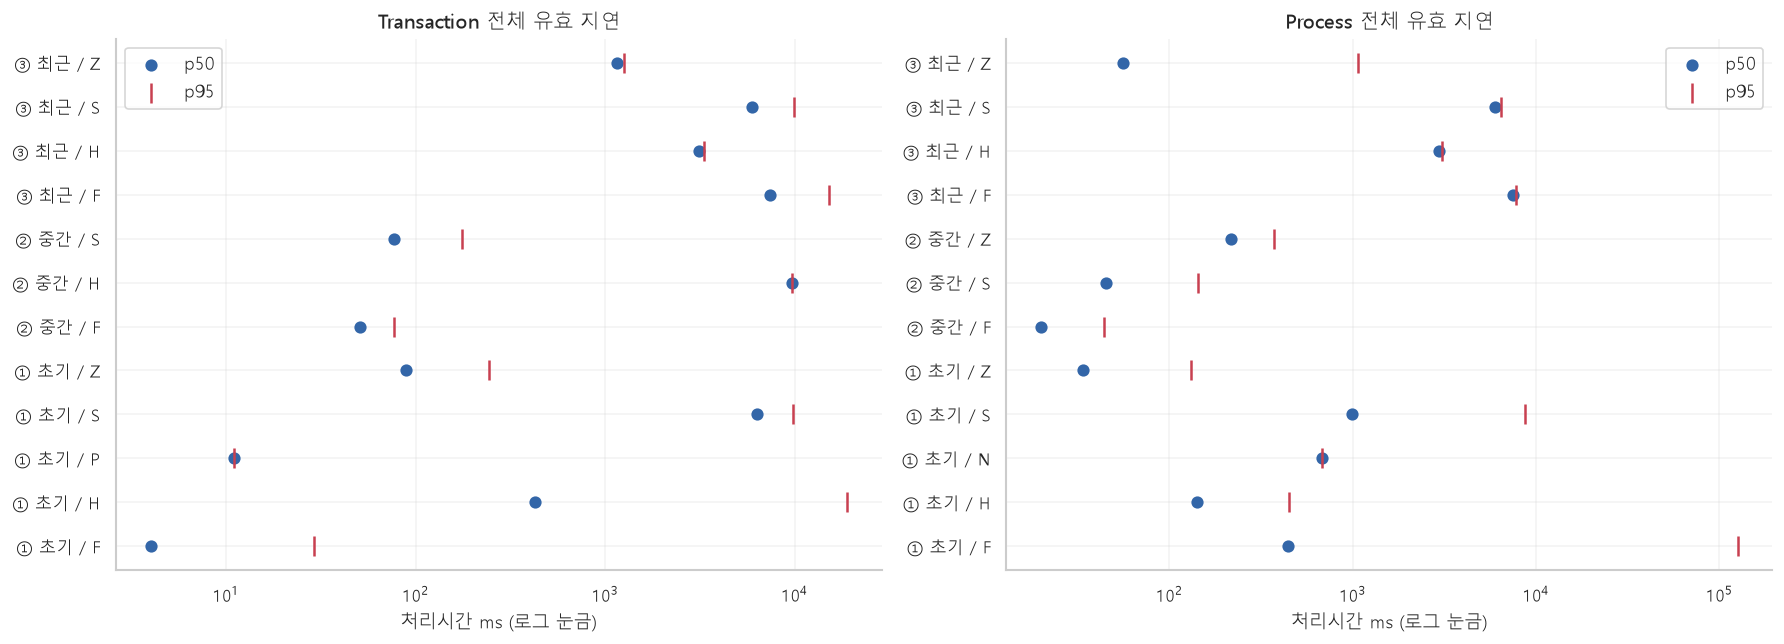

**상태별 지연**

점은 p50, 붉은 표시는 p95입니다. 표의 valid_duration가 실제 분위수 분모입니다.

**의미:** S/F 차이에 업무 구성·기간 변화가 섞입니다. F의 긴 시간은 장애 원인을 증명하지 않습니다.

**설계 반영:** 같은 업무·기간 안에서 상태를 나눈 다음 지연 차이를 비교합니다.

In [11]:
display(status_stats[["kind", "source_period", "status", "rows", "valid_duration", "p50_ms", "p95_ms", "p99_ms"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, kind in zip(axes, ["Transaction", "Process"]):
    s = status_stats.loc[status_stats.kind.eq(kind) & status_stats.status.isin(["S", "F", "H", "P", "N", "Z"])].copy()
    s["group"] = s.source_period.map(PERIOD_LABELS).astype("string") + " / " + s.status.astype("string")
    s = s.loc[s.valid_duration.gt(0)].sort_values(["source_period", "status"])
    ypos = np.arange(len(s))
    ax.scatter(s.p50_ms, ypos, label="p50", color="#3366a8", s=40)
    ax.scatter(s.p95_ms, ypos, label="p95", color="#c84050", marker="|", s=150)
    ax.set_yticks(ypos, s.group); ax.set_xscale("log")
    ax.set(title=kind + " 전체 유효 지연", xlabel="처리시간 ms (로그 눈금)"); ax.legend()
fig.tight_layout(); plt.show()
explain("상태별 지연", "점은 p50, 붉은 표시는 p95입니다. 표의 valid_duration가 실제 분위수 분모입니다.",
        "S/F 차이에 업무 구성·기간 변화가 섞입니다. F의 긴 시간은 장애 원인을 증명하지 않습니다.",
        "같은 업무·기간 안에서 상태를 나눈 다음 지연 차이를 비교합니다.")

### 4.1 같은 기간·같은 업무 안에서 S/F 비교

두 상태 모두 유효 지연 30건 이상인 업무만 비교합니다. 이 분석은 사후 설명용이며 학습 입력에 Status를 넣는 과정이 아닙니다.

n            p50          \
status                                        F        S     F       S   
source_period     interfaceId                                            
25년12월24일-26년4월6일 IF_DB2DB_908           1447.0  47429.0   5.0  5411.0   
                  IF_DB2DB_916           2107.0  47306.0   9.0  5472.0   
                  IF_DB2DB_906           2776.0  47305.0   9.0  5421.0   
                  IF_DB2DB_919           1466.0  47298.0   4.0  5450.0   
                  IF_DB2DB_905           2367.0  47298.0   6.0  5547.0   
                  IF_DB2DB_917           1618.0  47284.0   6.0  5442.0   
                  IF_DB2DB_902           1899.0  47268.0   4.0  5503.0   
                  IF_DB2DB_907           2196.0  47252.0   6.0  5457.0   
                  IF_DB2DB_904           1656.0  47230.0   4.0  5517.0   
                  IF_DB2DB_910           1326.0  47228.0   4.0  5389.0   
                  IF_DB2DB_909           1514.0  47138.0   4.0  5427.0   
                  IF_DB2DB_914           1833.0  47101.0   4.0  5558.0   
                  IF_DB2DB_918           1407.0  47081.0   5.0  5476.0   
                  IF_DB2DB_901           1743.0  47021.0   4.0  5464.0   
                  IF_DB2DB_915           2433.0  47001.0   5.0  5536.0   
                  IF_DB2DB_912           1584.0  46950.0   4.0  5601.5   
                  IF_DB2DB_911           1646.0  46884.0   4.0  5555.0   
                  IF_DB2DB_903           1060.0  46860.0   4.0  5550.5   
                  IF_DB2DB_913           1111.0  46502.0   4.0  5590.0   
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001  41625.0  42741.0  61.0    75.0   

                                           p95          derived  
status                                       F        S F/S_p50  
source_period     interfaceId                                    
25년12월24일-26년4월6일 IF_DB2DB_908           66.10  9709.60   0.001  
                  IF_DB2DB_916           70.70  9726.00   0.002  
                  IF_DB2DB_906           60.25  9692.00   0.002  
                  IF_DB2DB_919           58.00  9807.00   0.001  
                  IF_DB2DB_905           49.00  9821.00   0.001  
                  IF_DB2DB_917           76.15  9754.00   0.001  
                  IF_DB2DB_902           29.00  9679.65   0.001  
                  IF_DB2DB_907           44.25  9743.00   0.001  
                  IF_DB2DB_904           50.00  9766.55   0.001  
                  IF_DB2DB_910           99.75  9756.00   0.001  
                  IF_DB2DB_909           58.80  9750.00   0.001  
                  IF_DB2DB_914           30.00  9776.00   0.001  
                  IF_DB2DB_918           84.40  9738.00   0.001  
                  IF_DB2DB_901           31.00  9695.00   0.001  
                  IF_DB2DB_915           45.00  9822.00   0.001  
                  IF_DB2DB_912           29.00  9753.00   0.001  
                  IF_DB2DB_911           34.50  9762.55   0.001  
                  IF_DB2DB_903          342.60  9712.00   0.001  
                  IF_DB2DB_913          172.50  9744.00   0.001  
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001   81.00   169.00   0.813

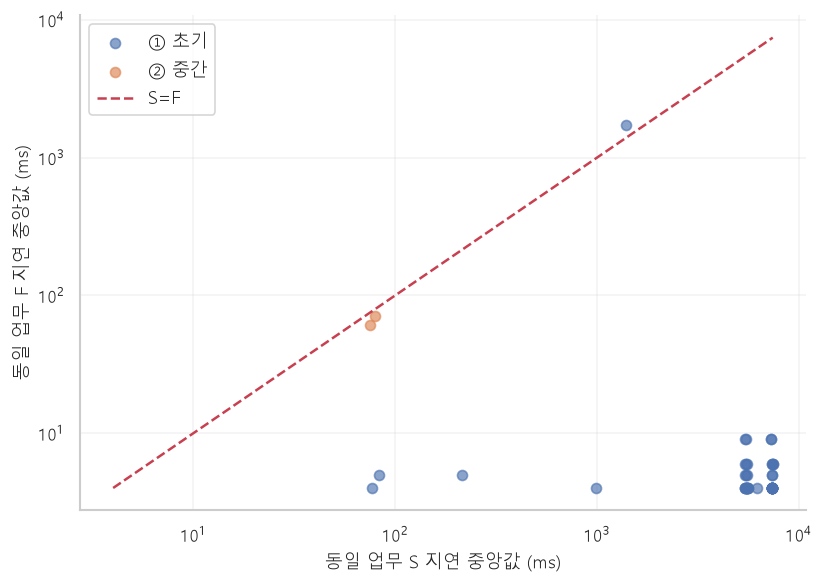

**업무 안의 S/F 비교**

양쪽 유효 지연 30건 이상인 기간·업무 쌍: 47개.

**의미:** 점선 위는 해당 업무의 F 중앙값이 S보다 긴 경우, 아래는 실패가 더 빨리 끝나는 경우입니다.

**설계 반영:** 전체 Status 차이를 업무 차이로 오해하지 않도록 이 비교를 같이 봅니다. 요청 크기/부하까지 통제한 인과 분석은 아닙니다.

In [12]:
sf = transactions.loc[transactions.status.isin(["S", "F"]) & transactions.duration_ms.ge(0)]
sf_groups = sf.groupby(["source_period", "interfaceId", "status"], observed=True).duration_ms.agg(
    n="count", p50="median", p95=lambda x: x.quantile(.95))
sf_compare = sf_groups.unstack("status")
if all(("n", v) in sf_compare for v in ["S", "F"]):
    sf_compare = sf_compare.loc[sf_compare[("n", "S")].ge(30) & sf_compare[("n", "F")].ge(30)].copy()
    sf_compare[("derived", "F/S_p50")] = sf_compare[("p50", "F")] / sf_compare[("p50", "S")].replace(0, np.nan)
display(sf_compare.sort_values(("n", "S"), ascending=False).head(20).round(3))
if len(sf_compare):
    fig, ax = plt.subplots(figsize=(7, 5))
    for period, group in sf_compare.groupby(level="source_period", observed=True):
        ax.scatter(group[("p50", "S")], group[("p50", "F")], label=PERIOD_LABELS[str(period)], alpha=.65)
    ax.set(xscale="log", yscale="log", xlabel="동일 업무 S 지연 중앙값 (ms)", ylabel="동일 업무 F 지연 중앙값 (ms)")
    limits = [min(sf_compare[("p50", "S")].min(), sf_compare[("p50", "F")].min()),
              max(sf_compare[("p50", "S")].max(), sf_compare[("p50", "F")].max())]
    ax.plot(limits, limits, "--", color="#c84050", label="S=F"); ax.legend(); fig.tight_layout(); plt.show()
explain("업무 안의 S/F 비교", f"양쪽 유효 지연 30건 이상인 기간·업무 쌍: {len(sf_compare):,}개.",
        "점선 위는 해당 업무의 F 중앙값이 S보다 긴 경우, 아래는 실패가 더 빨리 끝나는 경우입니다.",
        "전체 Status 차이를 업무 차이로 오해하지 않도록 이 비교를 같이 봅니다. 요청 크기/부하까지 통제한 인과 분석은 아닙니다.")

## 5. 데이터가 추가되어도 움직이지 않는 극단값 기준선

**상위 1%/0.1%는 데이터 불변 규칙이 아닙니다.** 학습 S 로그에서 p99/p99.9를 계산해 저장된
기준선 버전으로 고정하면, 그 버전을 적용하는 동안만 임계값이 고정됩니다.

현재 EDA는 관측 날짜 기준 과거 학습/검증/시험 분할을 재사용합니다. 기준선에는 검증/시험을 넣지 않습니다.
같은 거래가 경계를 넘으면 제외합니다. future leakage 없이 새 업무의 기준선을 만들 수 없는 한계를 드러냅니다.

In [13]:
tx_split = chronological_split(transactions)
pr_split = chronological_split(processes)
split_audit = []
for kind, frame, split, flags in [("Transaction", transactions, tx_split, tx_rules), ("Process", processes, pr_split, pr_rules)]:
    for name, idx in split.groupby(split).groups.items():
        split_audit.append({"kind": kind, "split": name, "rows": len(idx),
            "reference_S": int(flags.loc[idx, "reference_eligible"].sum()),
            "first": frame.loc[idx, "startTime"].min(), "last": frame.loc[idx, "startTime"].max()})
display(pd.DataFrame(split_audit))
tx_reference = tx_split.eq("train") & tx_rules.reference_eligible
pr_reference = pr_split.eq("train") & pr_rules.reference_eligible

,kind,split,rows,reference_S,first,last
0,Transaction,test,111303,36765,2026-08-20 00:00:00.284,2026-10-02 15:36:59.444
1,Transaction,train,1616874,1304416,2025-12-24 10:25:31.632,2026-03-20 17:04:21.488
2,Transaction,validation,280526,221858,2026-03-23 08:12:59.258,2026-08-19 23:59:55.035
3,Process,excluded_boundary_transaction,4,3,2026-01-12 10:28:56.989,2026-04-02 11:14:00.511
4,Process,excluded_missing_time_or_id,325,0,NaT,NaT
5,Process,test,111549,36987,2026-08-20 00:00:00.295,2026-10-02 15:36:59.559
6,Process,train,3175652,2608471,2025-12-24 10:25:31.689,2026-03-20 17:04:27.315
7,Process,validation,426669,367712,2026-03-23 08:12:59.703,2026-08-19 23:59:55.042


### 5.1 구체 업무 → 공통 범주/어댑터 → 통합으로 기준선 fallback

Transaction: interfaceId → interfaceType+시작/종료 채널 → 통합.
Process: processId → adapterType+channelId → 통합.
그룹 기준선에 지원량이 없으면 상위 기준으로 넘어가며 상위에서도 없으면 비교 불가로 남깁니다.
통합 기준은 서로 다른 업무가 섞인 약한 fallback이므로 SLA 대신 확정 차단 기준으로 쓰지 않습니다.

In [14]:
TX_LEVELS = [("업무", ["interfaceId"]), ("공통경로", ["interfaceType", "startChannelId", "endChannelId"]), ("통합", [])]
PR_LEVELS = [("업무단계", ["processId"]), ("공통어댑터", ["adapterType", "channelId"]), ("통합", [])]
tx_thresholds = {name: freeze_quantiles(transactions, tx_reference, columns, CONFIG) for name, columns in TX_LEVELS}
pr_thresholds = {name: freeze_quantiles(processes, pr_reference, columns, CONFIG) for name, columns in PR_LEVELS}
display(tx_thresholds["업무"].sort_values("n", ascending=False).head(15).round(3))
display(pr_thresholds["공통어댑터"].sort_values("n", ascending=False).head(15).round(3))
display(pd.concat([tx_thresholds["통합"].assign(kind="Transaction"), pr_thresholds["통합"].assign(kind="Process")]))

,n,median,q0.99,q0.999
group,,,,
"[""IF_DB2DB_908""]",39908,6159.5,13108.09,257584.609
"[""IF_DB2DB_902""]",39872,6206.0,12799.51,233696.112
"[""IF_DB2DB_901""]",39785,6189.0,12805.92,240371.048
"[""IF_DB2DB_916""]",39759,6218.0,13544.20,249266.504
"[""IF_DB2DB_906""]",39756,6183.0,13116.85,249403.605
"[""IF_DB2DB_911""]",39652,6282.0,13914.30,233115.988
"[""IF_DB2DB_919""]",39596,6253.0,14084.35,252217.815
"[""IF_DB2DB_905""]",39591,6310.0,13746.70,236918.410
"[""IF_DB2DB_917""]",39586,6213.0,13747.95,244017.870


,n,median,q0.99,q0.999
group,,,,
"[""DB.READER"", ""TSC""]",1279522,438.0,1127.00,2384.479
"[""DB.WRITER"", ""SOL""]",1279433,6240.0,10402.00,20644.112
"[""FILE.READER"", ""TSC""]",24386,454.0,24201.60,27285.400
"[""FILE.WRITER"", ""SOL""]",22341,906.0,1534.20,2137.900
"[""SERVICE.EXECUTOR"", ""HUB""]",2595,7038.0,7107.54,NaN
"[""SERVICE.EXECUTOR"", ""SOL""]",45,105.0,NaN,NaN
"[""DB.READER"", ""SOL""]",32,214.0,NaN,NaN
"[""FILE.READER"", ""SOL""]",17,4695.0,NaN,NaN
"[""FILE.WRITER"", ""TSC""]",17,6854.0,NaN,NaN


,n,median,q0.99,q0.999,kind
group,,,,,
GLOBAL,1304416,6714.0,11337.0,152269.87,Transaction
GLOBAL,2608471,1029.0,9728.0,18388.12,Process


,kind,q,period,test_rows,comparable,candidates,candidate_pct,business_reference,common_reference,global_reference,no_reference
0,Transaction,0.990,② 중간,84035,84035,34,0.0405,0,83996,39,0
1,Transaction,0.990,③ 최근,27268,27268,1182,4.3348,0,36,27232,0
2,Transaction,0.999,② 중간,84035,84035,0,0.0000,0,58,83977,0
3,Transaction,0.999,③ 최근,27268,27268,0,0.0000,0,36,27232,0
4,Process,0.990,② 중간,84144,84064,40,0.0476,0,84030,114,0
5,Process,0.990,③ 최근,27405,27405,1002,3.6563,0,126,27279,0
6,Process,0.999,② 중간,84144,84064,39,0.0464,0,120,84024,0
7,Process,0.999,③ 최근,27405,27405,356,1.2990,0,126,27279,0


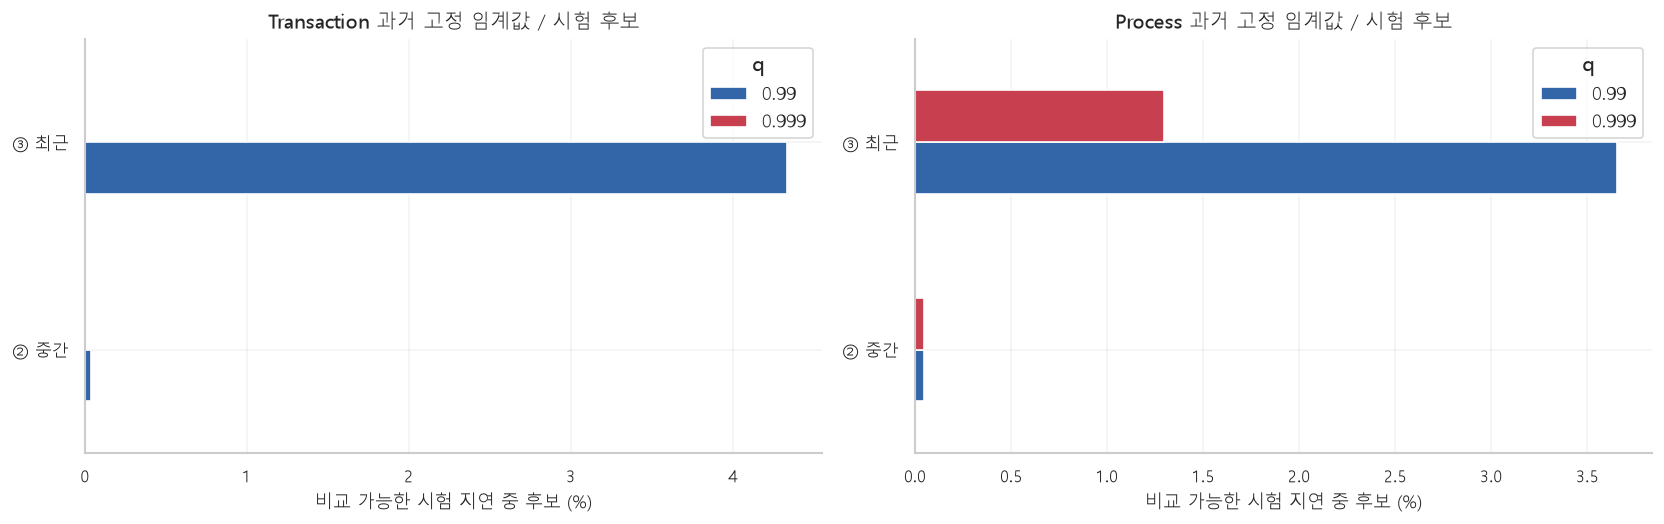

**고정 분위수 시험 결과**

후보는 threshold를 엄격히 초과한 실행입니다. 동률·분포 변화 때문에 시험 후보율은 1%/0.1%와 같지 않습니다.

**의미:** 새 업무가 초기 그룹에 없으면 대부분 공통/통합 기준선으로 떨어질 수 있습니다. 그것은 콜드스타트가 해결됐다는 뜻이 아닙니다.

**설계 반영:** 이 기준은 통계 후보/우선 검토용으로 사용합니다. 중요 업무의 하드 타임아웃은 승인된 SLA로 별도 설정합니다.

In [15]:
quantile_rows, quantile_views = [], {}
for kind, frame, split, profiles, levels in [("Transaction", transactions, tx_split, tx_thresholds, TX_LEVELS),
                                           ("Process", processes, pr_split, pr_thresholds, PR_LEVELS)]:
    for q in CONFIG["latency_quantiles"]:
        result = score_frozen_quantiles(frame, profiles, levels, q)
        quantile_views[(kind, q)] = result
        for period, idx in frame.loc[split.eq("test")].groupby("source_period", observed=True).groups.items():
            s = result.loc[idx]; comparable = int(s.comparable.sum()); candidates = int(s.candidate.sum())
            quantile_rows.append({"kind": kind, "q": q, "period": PERIOD_LABELS[str(period)], "test_rows": len(idx),
                "comparable": comparable, "candidates": candidates, "candidate_pct": 100*candidates/comparable if comparable else np.nan,
                "business_reference": int(s.reference_level.isin(["업무", "업무단계"]).sum()),
                "common_reference": int(s.reference_level.isin(["공통경로", "공통어댑터"]).sum()),
                "global_reference": int(s.reference_level.eq("통합").sum()), "no_reference": int(s.reference_level.eq("NO_REFERENCE").sum())})
quantile_audit = pd.DataFrame(quantile_rows)
display(quantile_audit.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, kind in zip(axes, ["Transaction", "Process"]):
    s = quantile_audit.loc[quantile_audit.kind.eq(kind)]
    s.pivot(index="period", columns="q", values="candidate_pct").plot.barh(ax=ax, color=["#3366a8", "#c84050"])
    ax.set(title=kind + " 과거 고정 임계값 / 시험 후보", xlabel="비교 가능한 시험 지연 중 후보 (%)", ylabel="")
fig.tight_layout(); plt.show()
explain("고정 분위수 시험 결과", "후보는 threshold를 엄격히 초과한 실행입니다. 동률·분포 변화 때문에 시험 후보율은 1%/0.1%와 같지 않습니다.",
        "새 업무가 초기 그룹에 없으면 대부분 공통/통합 기준선으로 떨어질 수 있습니다. 그것은 콜드스타트가 해결됐다는 뜻이 아닙니다.",
        "이 기준은 통계 후보/우선 검토용으로 사용합니다. 중요 업무의 하드 타임아웃은 승인된 SLA로 별도 설정합니다.")

### 5.2 p99.9 지원량 민감도와 기본값 선택

최소 10,000행은 0.1% 꼬리에 약 10개 관측이 대응하는 시작 기준일 뿐, 독립성·안정성을 보장하지 않습니다.
아래 비교는 지원량을 1,000/5,000/10,000으로 바꿀 때 기준선이 가능한 그룹 수가 어떻게 달라지는지 보여줍니다.

In [16]:
sensitivity = []
for kind, profiles in [("Transaction", tx_thresholds), ("Process", pr_thresholds)]:
    for name, profile in profiles.items():
        for support in [1000, 5000, 10000]:
            sensitivity.append({"kind": kind, "level": name, "min_support": support, "supported_groups": int(profile.n.ge(support).sum()), "groups": len(profile)})
display(pd.DataFrame(sensitivity))

,kind,level,min_support,supported_groups,groups
0,Transaction,업무,1000,42,99
1,Transaction,업무,5000,41,99
2,Transaction,업무,10000,41,99
3,Transaction,공통경로,1000,2,12
4,Transaction,공통경로,5000,1,12
5,Transaction,공통경로,10000,1,12
6,Transaction,통합,1000,1,1
7,Transaction,통합,5000,1,1
8,Transaction,통합,10000,1,1
9,Process,업무단계,1000,83,218


## 6. 어떤 기준으로 모델을 나눌 것인가

1. **업무별:** Transaction interfaceId, Process processId. 의미가 명확하지만 새 ID마다 콜드스타트.
2. **범주 조합별:** Tx interfaceType+채널 경로, category_top+interfaceType+경로.
   Process adapterType+channelId, 필요하면 허브 추가. 새 업무라도 동일 역할·경로를 공유하면 재사용 가능.
3. **통합:** 공통 행동 수치·시간 피처. 새 업무의 세부 ID에 의존하지 않고 최후 fallback으로 사용.

categoryName의 NONE/MISSING도 유지하지만 정보량을 따로 확인합니다. processCount 같은 숫자나 실행 결과 Status는
기본 범주 라우팅 키로 쓰지 않습니다. 미래에 관측할 종료 피처로 진행 중 탐지를 라우팅하지 않습니다.

In [17]:
tx_group_evidence, tx_group_details = grouping_profile(transactions, "transaction", tx_split, tx_rules, CONFIG)
pr_group_evidence, pr_group_details = grouping_profile(processes, "process", pr_split, pr_rules, CONFIG)
group_evidence = pd.concat([tx_group_evidence, pr_group_evidence], ignore_index=True)
display(group_evidence.round(4))
display(tx_group_details["업무"].head(15).round(3))
display(pr_group_details["어댑터+채널"].head(15).round(3))

,kind,grouping,columns,groups_all,groups_ready,train_reference_rows,test_rows,test_group_ready_pct,test_unseen_pct,train_log_variance_explained
0,transaction,업무,interfaceId,406,20,1304416,111303,0.0000,99.9398,0.2581
1,transaction,카테고리,category_top + interfaceType,17,2,1304416,111303,64.4727,35.4743,0.1816
2,transaction,카테고리+경로,category_top + interfaceType + startChannelId ...,45,2,1304416,111303,39.9908,35.4896,0.1876
3,transaction,경로,interfaceType + startChannelId + endChannelId,23,2,1304416,111303,75.4984,0.0135,0.0059
4,transaction,통합,공통 행동 피처,1,1,1304416,111303,100.0000,0.0000,0.0000
5,process,업무단계,processId,687,40,2608471,111549,0.0000,99.8718,0.9296
6,process,어댑터,adapterType,24,5,2608471,111549,99.8315,0.0215,0.9204
7,process,어댑터+채널,adapterType + channelId,62,3,2608471,111549,75.3893,0.1165,0.9205
8,process,어댑터+채널+허브,adapterType + channelId + processHubId,68,3,2608471,111549,75.3893,0.1165,0.9205
9,process,통합,공통 행동 피처,1,1,2608471,111549,100.0000,0.0000,0.0000


,rows,train_S,validation_S,train_days,std,median,ready
group,,,,,,,
"[""IF_CLAUDE_CREATE_001""]",84366,0,35837,NaN,NaN,NaN,False
"[""IF_REST_ERROR_RESPONSE""]",82586,0,0,NaN,NaN,NaN,False
"[""IF_DB2DB_906""]",50118,39756,7549,6.0,0.462,8.730,True
"[""IF_DB2DB_905""]",49706,39591,7707,6.0,0.460,8.750,True
"[""IF_DB2DB_907""]",49481,39550,7702,6.0,0.467,8.735,True
"[""IF_DB2DB_915""]",49470,39318,7683,6.0,0.461,8.752,True
"[""IF_DB2DB_916""]",49452,39759,7547,6.0,0.463,8.735,True
"[""IF_DB2DB_902""]",49202,39872,7396,6.0,0.459,8.733,True
"[""IF_DB2DB_914""]",48969,39393,7708,6.0,0.457,8.747,True


,rows,train_S,validation_S,train_days,std,median,ready
group,,,,,,,
"[""DB.READER"", ""TSC""]",1638563,1279522,145425,26.0,0.312,6.084,True
"[""DB.WRITER"", ""SOL""]",1614679,1279433,145343,25.0,0.417,8.739,True
"[""SERVICE.EXECUTOR"", ""HUB""]",232928,2595,71805,12.0,1.802,8.859,True
"[""GATEWAY.INVOKER"", ""SOL""]",57253,0,0,NaN,NaN,NaN,False
"[""SERVICE.EXECUTOR"", ""SOL""]",49981,45,8,8.0,1.114,4.663,False
"[""FILE.WRITER"", ""SOL""]",25154,22341,79,11.0,0.231,6.810,False
"[""FILE.READER"", ""TSC""]",25121,24386,73,13.0,0.776,6.120,False
"[""DB.EXECUTOR"", ""SOL""]",22784,1,5,1.0,NaN,5.011,False
"[""DB.WRITER"", ""TSC""]",13120,2,28,2.0,0.441,5.849,False


### 6.1 세밀한 모델의 이득과 지원 부족을 같이 보기

`train_log_variance_explained`는 학습 후보의 log1p 지연 분산 중 그룹 간 평균 차이가 설명하는 비중입니다.
높으면 그룹마다 시간 규모가 다르다는 근거입니다. 그룹을 무한히 잘게 나누면 높아지므로 성능 점수로 쓰지 않습니다.

`test_group_ready_pct`는 설정한 학습·검증·관측일 최소량을 충족한 그룹에 속하는 시험 행 비중입니다.
그룹 AI를 학습했다는 뜻도, 정상 검출 정확도도 아닙니다. 시험 표본 자체는 모든 Status를 포함합니다.

`test_unseen_pct`는 해당 그룹의 적격 학습 S 로그가 0인 시험 행 비율입니다. 완전히 새 ID뿐 아니라 과거 관측은 있지만 학습 기준 후보가 없는 그룹도 포함합니다.

**현재 출력에서 읽는 분할 방향:** 업무 ID별 지원 그룹의 시험 커버리지는 Transaction·Process 모두 0%입니다. 새 업무를 처리하려면 fallback이 필수입니다.
Process는 `adapterType`만 나누면 시험 지원율 99.83%, 학습 log-지연 분산 설명 비중 92.04%입니다. 채널을 추가하면 지원율은 75.39%로 내려가고 분산 설명은 거의 늘지 않아, 어댑터별 공통 모델부터 비교하고 채널/업무 전문가를 충분한 근거가 있을 때 추가하는 실험이 합리적입니다.
Transaction 경로 그룹은 지원율 75.50%지만 분산 설명 비중은 약 0.59%입니다. category_top+interfaceType은 약 18.16%를 설명하되 지원율은 64.47%이므로, 경로의 높은 지원율만으로 최적 분할이라고 결정하면 안 됩니다. 두 후보와 통합 모델을 같은 시간 분할에서 비교합니다.
수치는 아래 셀의 default 설정 실행 결과이며, 규칙·분할 설정을 바꾸면 다시 계산해야 합니다.

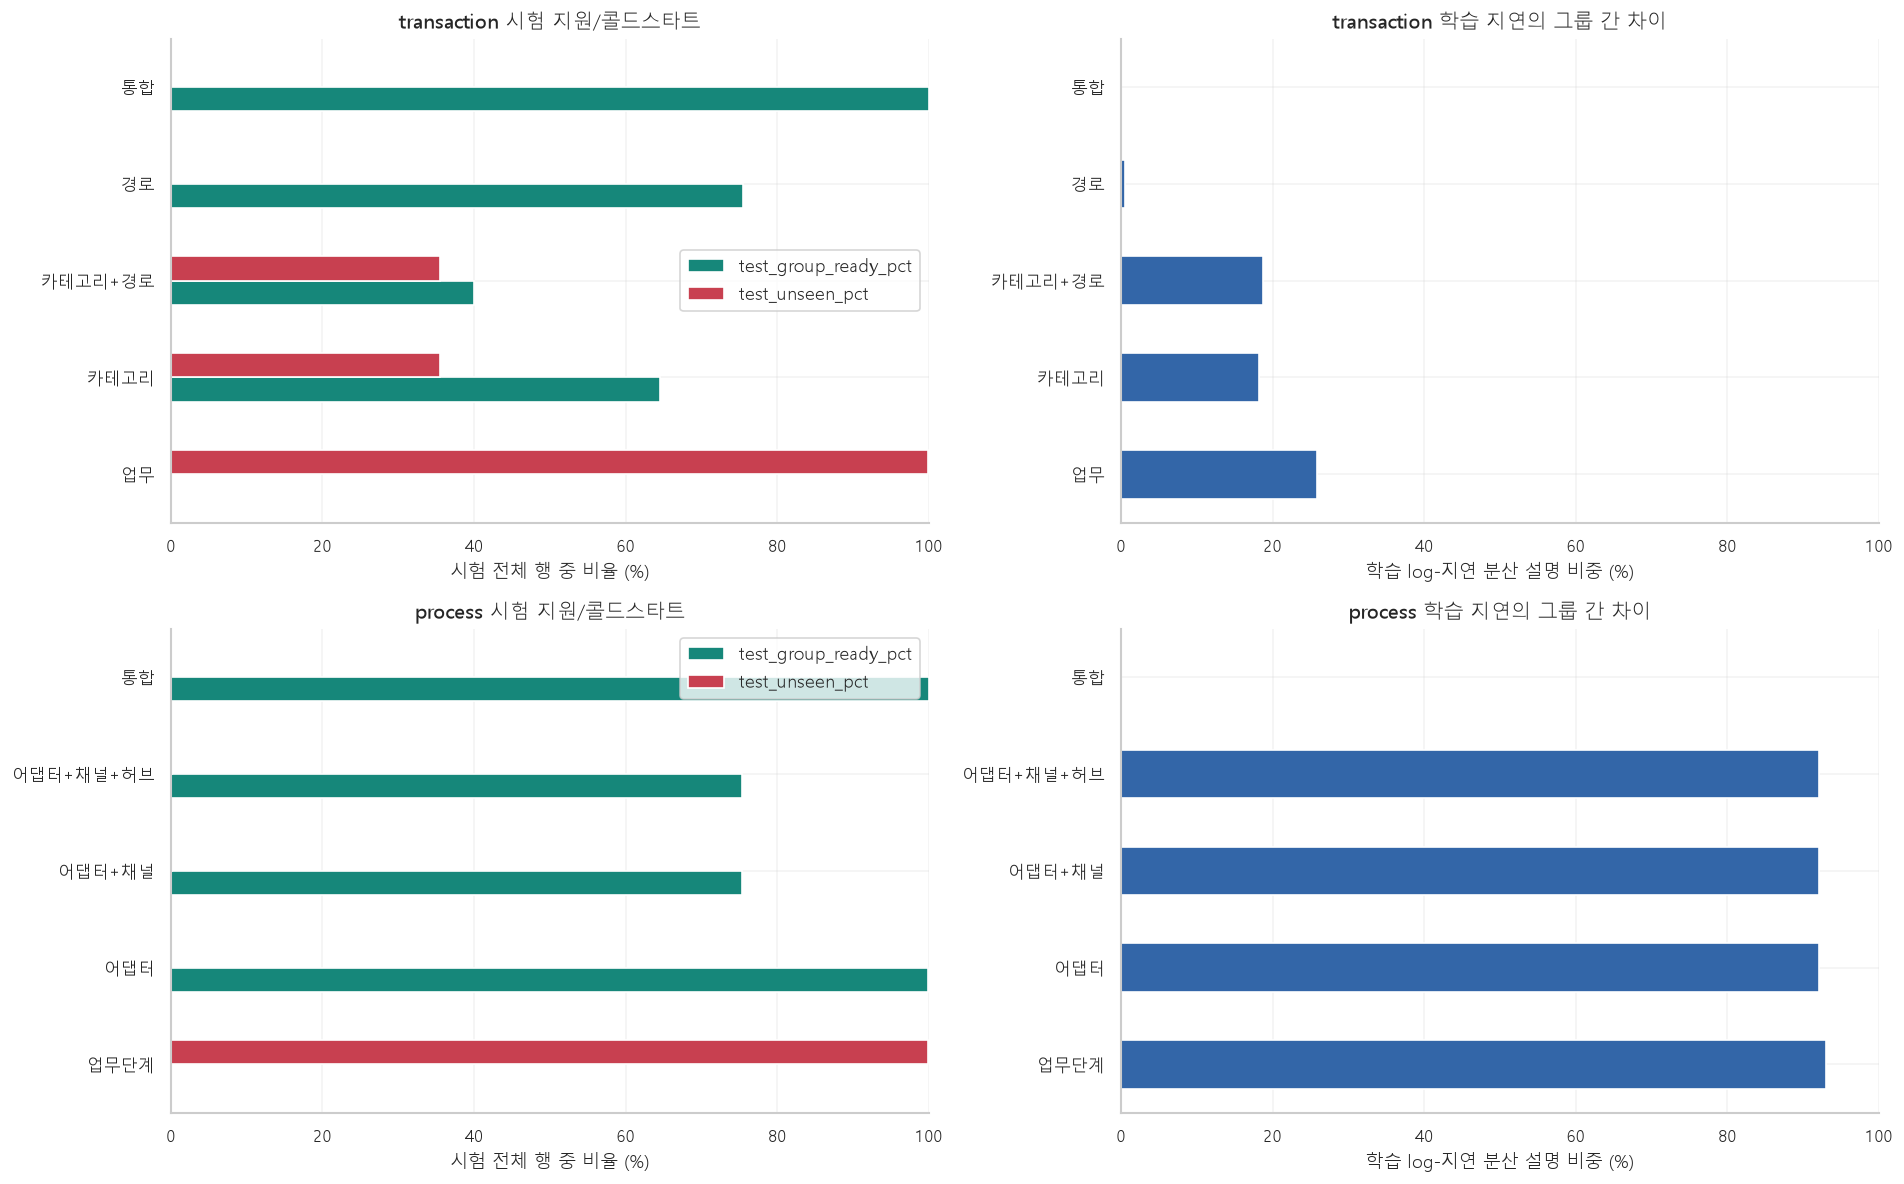

**분할 후보의 실제 지원량**

ready 판정은 학습 S≥500, 검증 S≥100, 학습 관측일≥3의 default입니다. 사용자 설정에 따라 바뀝니다.

**의미:** 범주 조합이 업무 ID보다 신규 그룹 비율을 낮출 수 있지만, 하나의 그룹 안에 서로 다른 실행 모드가 섞일 수 있습니다.

**설계 반영:** 지원량·내부 지연 분산·운영 의미를 함께 보고 그룹을 승인합니다. 현 자료에서 가장 정확한 모델은 아직 결정할 수 없습니다.

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for row, kind in enumerate(["transaction", "process"]):
    s = group_evidence.loc[group_evidence.kind.eq(kind)].set_index("grouping")
    s[["test_group_ready_pct", "test_unseen_pct"]].plot.barh(ax=axes[row, 0], color=["#16877a", "#c84050"])
    axes[row, 0].set(title=kind + " 시험 지원/콜드스타트", xlabel="시험 전체 행 중 비율 (%)", ylabel="", xlim=(0, 100))
    s.train_log_variance_explained.mul(100).plot.barh(ax=axes[row, 1], color="#3366a8")
    axes[row, 1].set(title=kind + " 학습 지연의 그룹 간 차이", xlabel="학습 log-지연 분산 설명 비중 (%)", ylabel="", xlim=(0, 100))
fig.tight_layout(); plt.show()
explain("분할 후보의 실제 지원량", "ready 판정은 학습 S≥500, 검증 S≥100, 학습 관측일≥3의 default입니다. 사용자 설정에 따라 바뀝니다.",
        "범주 조합이 업무 ID보다 신규 그룹 비율을 낮출 수 있지만, 하나의 그룹 안에 서로 다른 실행 모드가 섞일 수 있습니다.",
        "지원량·내부 지연 분산·운영 의미를 함께 보고 그룹을 승인합니다. 현 자료에서 가장 정확한 모델은 아직 결정할 수 없습니다.")

### 6.2 ready 기준 민감도: 최소량을 작게 잡는다고 충분한 모델이 되는 것은 아님

In [19]:
ready_sensitivity = []
for kind, details in [("Transaction", tx_group_details), ("Process", pr_group_details)]:
    for name, profile in details.items():
        for min_train, min_val, min_days in [(100, 30, 2), (500, 100, 3), (2000, 300, 5)]:
            ready = profile.train_S.ge(min_train) & profile.validation_S.ge(min_val) & profile.train_days.ge(min_days)
            ready_sensitivity.append({"kind": kind, "grouping": name, "train_min": min_train, "validation_min": min_val,
                                      "days_min": min_days, "ready_groups": int(ready.sum()), "groups": len(profile)})
display(pd.DataFrame(ready_sensitivity))

,kind,grouping,train_min,validation_min,days_min,ready_groups,groups
0,Transaction,업무,100,30,2,20,406
1,Transaction,업무,500,100,3,20,406
2,Transaction,업무,2000,300,5,20,406
3,Transaction,카테고리,100,30,2,2,17
4,Transaction,카테고리,500,100,3,2,17
5,Transaction,카테고리,2000,300,5,2,17
6,Transaction,카테고리+경로,100,30,2,3,45
7,Transaction,카테고리+경로,500,100,3,2,45
8,Transaction,카테고리+경로,2000,300,5,2,45
9,Transaction,경로,100,30,2,2,23


## 7. 권장 구현: 계층 fallback + 검증된 전문가 앙상블

**규칙 평가 → (격리 / 결과 알림 / 품질 검토를 보존) → 유효 로그의 모델 채점** 순서입니다.
학습 제외와 채점 제외는 다릅니다. F/H는 규칙 경보가 이미 있어도 모델 설명을 얻기 위해 유효할 때 채점할 수 있습니다.

### 7.1 모델별 역할

| 모델 | 기본 분할 키 | 공통 입력 후보 | 적용 조건 |
|---|---|---|---|
| 업무 전문가 | Tx interfaceId / Process processId | 지연·처리량·시간·병목/누락 피처 | 학습량·기간·검증량과 운영 검토 통과 |
| 공통 전문가 | Tx category_top+interfaceType 또는 interfaceType+시작/종료 채널 비교 / Process adapterType 우선, 채널 조합은 추가 후보 | 동일 역할의 행동 수치 | 같은 범주의 신규 업무에도 fallback; 후보별 지원량과 검증 비교 |
| 통합 모델 | 전체 유효 업무 | 공통 행동 피처·결측 플래그·주기 피처 | 모든 업무의 비교 기준과 최후 fallback |

통합 모델의 콜드스타트 버전에서는 interfaceId/processId의 희귀도만으로 새 업무를 장애라고 판정하지 않습니다.
학습에서 항상 0인 unseen 플래그는 트리 모델이 새 업무의 의미를 학습했다는 증거가 아니므로 별도 라우팅 메타데이터로 관리합니다.

### 7.2 콜드스타트 단계

1. **신규 ID:** 업무 전문가 가중치=0. 지원되는 공통 전문가와 통합 모델로 채점하고 `new_business=True`를 별도 표시합니다.
2. **범주도 신규:** 통합 모델+불변 규칙+승인 SLA로 시작합니다. 통합 모델도 OOD/분포 외삽일 수 있어 기준선 부족 상태를 노출합니다.
3. **이력 축적:** 시간에 따라 별도의 학습/검증을 확보합니다. 첫 관측을 즉시 정상 학습에 넣지 않습니다.
4. **shadow 검증:** 새 업무 모델의 경보량·실패/성공 교차·실제 사건 검토를 통합/공통 모델과 비교합니다.
5. **승격:** 지원량·검증·드리프트 확인 후 업무 전문가를 활성화합니다. 이력이 있어도 검증이 없으면 자동 승격하지 않습니다.

### 7.3 앙상블: raw 점수를 그대로 더하지 않기

모델마다 점수 척도가 다르므로 각 모델의 **과거 별도 calibration 구간 점수 분포**에서 percentile로 변환한 뒤 결합합니다.
percentile은 이상 확률이 아닙니다. IF/LOF/딥러닝의 raw 점수 평균은 의미가 일치하지 않을 수 있습니다.

예시: `score = w_business × rank_business + w_common × rank_common + w_global × rank_global`.
가용 모델만 가중치를 다시 정규화합니다. 신규 업무에서는 w_business=0입니다.
가중치는 데이터량만으로 확정하지 않고 검증 안정성·운영 검토로 결정합니다.
최종 결합 임계값은 또 다른 시간 holdout에서 정해야 하므로 여기서는 임의 가중치의 성능을 주장하지 않습니다.

하드 규칙을 만족한 경보는 낮은 모델 점수 때문에 취소하지 않습니다. 반대로 통계 후보를 하드 차단으로 승격하지 않습니다.

In [20]:
routing_evidence = group_evidence[["kind", "grouping", "groups_ready", "test_group_ready_pct", "test_unseen_pct"]].copy()
display(routing_evidence.round(3))
example_routes = pd.DataFrame([
    ["기존 업무·검증 전문가 있음", "업무 + 공통 + 통합", "calibrated ensemble", "업무 모델 우선, 통합도 함께 비교"],
    ["새 업무·공통 그룹 지원됨", "공통 + 통합", "business weight=0", "신규 업무 표시는 이상 정답 아님"],
    ["새 업무·새 범주", "통합 + 불변/승인 정책 규칙", "OOD / 기준선 부족 표시", "전문가를 새로 학습한 것처럼 처리하지 않음"],
    ["키/시각/상태 사전 위반", "격리 + 품질 경보", "모델 입력 제한", "원본 삭제 금지"],
], columns=["상황", "사용 모델/경로", "결합", "주의"])
display(example_routes)

,kind,grouping,groups_ready,test_group_ready_pct,test_unseen_pct
0,transaction,업무,20,0.000,99.940
1,transaction,카테고리,2,64.473,35.474
2,transaction,카테고리+경로,2,39.991,35.490
3,transaction,경로,2,75.498,0.013
4,transaction,통합,1,100.000,0.000
5,process,업무단계,40,0.000,99.872
6,process,어댑터,5,99.831,0.022
7,process,어댑터+채널,3,75.389,0.117
8,process,어댑터+채널+허브,3,75.389,0.117
9,process,통합,1,100.000,0.000


,상황,사용 모델/경로,결합,주의
0,기존 업무·검증 전문가 있음,업무 + 공통 + 통합,calibrated ensemble,"업무 모델 우선, 통합도 함께 비교"
1,새 업무·공통 그룹 지원됨,공통 + 통합,business weight=0,신규 업무 표시는 이상 정답 아님
2,새 업무·새 범주,통합 + 불변/승인 정책 규칙,OOD / 기준선 부족 표시,전문가를 새로 학습한 것처럼 처리하지 않음
3,키/시각/상태 사전 위반,격리 + 품질 경보,모델 입력 제한,원본 삭제 금지


### 7.4 추후 클러스터링·딥러닝 확장

- **클러스터링:** 학습 구간의 공통 행동 수치를 log/강건 스케일링한 뒤 반복 실행 모드를 나눕니다. Status를 클러스터 정답으로 쓰지 않습니다. 신규 로그는 기존 군집과의 거리/지원량을 확인하고 멀면 unknown으로 보류합니다. 새 데이터마다 전체 군집을 재계산하지 않습니다.
- **딥러닝:** 오토인코더/Deep SVDD 같은 공통 표현 기반 탐지를 비교할 수 있습니다. 데이터가 많다는 이유만으로 초기 IF보다 유리하다고 단정하지 않습니다. 초반에는 수집 품질·그룹 의미·평가 라벨 확보가 우선입니다.
- **실시간:** 완료 후 duration/병목 피처와 진행 중 elapsed/과거 창 피처의 모델을 분리합니다. endTime과 최종 Status를 미래 시점에 사용하는 실험은 실시간 성능이 아닙니다.

방법 참고: [scikit-learn의 outlier/novelty detection 구분](https://scikit-learn.org/stable/modules/outlier_detection.html),
[Deep One-Class Classification 원 논문](https://proceedings.mlr.press/v80/ruff18a.html).
공통 fallback·가중치·최소 지원량은 이 데이터에 대한 설계 제안이며 위 자료가 최적성을 보장하지 않습니다.

## 8. 구현 순서와 승인할 규칙

1. **지금 적용 가능한 입력 검증:** SQL 키 결측/충돌, 미정의 상태, 음수 시각 차이, 카운트 도메인 위반. 시계/단위/정수 계약도 문서화합니다.
2. **사용자 설정으로 적용:** F/H 결과 알림, 특정 업무·패턴·시간대·SLA. 금지 목록과 스케줄은 실제 운영자가 제공해야 합니다.
3. **계약 확인 후 강화:** count 보존·상태 전파·선행 관계·거래 시간 경계. 조건부 실행/미처리/부분성공/수집 지연을 구분합니다.
4. **통계 검토:** 학습 구간 p99/p99.9 고정 기준을 배포 버전으로 관리합니다. 입력 SLA 없이 ‘상위 0.1%=확정 장애’라고 하지 않습니다.
5. **모델 비교:** 통합 → 공통 범주 → 지원되는 업무 모델 순으로 개발하고 시간 holdout 및 새 업무 holdout에서 비교합니다.

평가에는 규칙/모델 후보뿐 아니라 비후보 표본도 포함합니다. confirmed labels가 생기면 precision/recall,
사건별 탐지 지연, 경보 수/시간, 업무별 커버리지, 신규 업무 오탐을 함께 측정합니다.

**이 노트북의 결과:** 실제 전량 규칙 건수, Status별 지연/결측, 같은 업무 S/F 비교,
과거 고정 분위수 시험 후보, 그룹 지원량/콜드스타트 근거. **미실행:** 새로운 그룹 AI 학습, 앙상블 성능, 클러스터링/딥러닝 성능.